# 02 · Manifold — Ji et al. 2020

Fit the cell-state trajectory, root it from developmental order, compute pseudotime.

**Scoping is re-derived here, not inherited.** The decisive question: does the large cycling compartment confound the embryonic modules (requiring it to be scoped out, as in Kürten), or does the embryonic geography hold across the whole manifold (keep it, as in Bischoff/Sun)? And is the topology **branching** (Gast-arm vs pSom-arm) or **linear** (Gast/pSom co-vary, Crest inverse-terminal)? Both are read from the data + embedding, compared against the branching (Puram/Filbin) and linear (Kürten/Sun) references.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr, pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('loaded processed:', adata.shape)

loaded processed: (10531, 21042)


### Score embryonic modules (needed to read topology / scoping)

`score_genes` with the union control pool; graph-smooth for the geography read (raw scores are shown in the deliverable signature panels in 03).

In [3]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.asarray(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

Gast: 76/81 genes present
pSom: 88/98 genes present
Crest: 101/104 genes present


### Scoping decision — is cell cycle a confound that must be removed?

Kürten had to scope out a cycling lobe because there Gast was confounded by proliferation and the embryonic relationship broke. Test the same on Ji 2020: (i) does the reference relationship (Gast/pSom co-vary, both oppose Crest) hold in the cycling compartment as well as the non-cycling one; (ii) is Gast driven up by cell cycle?

In [4]:
g2m = pd.to_numeric(adata.obs.g2m_score, errors='coerce')
g1s = pd.to_numeric(adata.obs.g1s_score, errors='coerce')
adata.obs['cc'] = pd.concat([g1s,g2m],axis=1).max(1)
def rel(sub, lab):
    G,P,C = sub.obs.Gast_sm, sub.obs.pSom_sm, sub.obs.Crest_sm
    print(f'[{lab:12s} n={sub.n_obs:5d}]  Gast~pSom {pearsonr(G,P)[0]:+.2f} | '
          f'Gast~Crest {pearsonr(G,C)[0]:+.2f} | pSom~Crest {pearsonr(P,C)[0]:+.2f}')
rel(adata, 'WHOLE'); rel(adata[~adata.obs.cycling], 'NON-CYCLING'); rel(adata[adata.obs.cycling], 'CYCLING')
m = adata.obs.cc.notna().values
print('\nProliferation confound (raw): '
      + ' | '.join(f'{v}~cc r={pearsonr(adata.obs[v].values[m], adata.obs.cc.values[m])[0]:+.2f}'
                    for v in ['Gast','pSom','Crest']))
print('DECISION: reference relationship holds in ALL compartments and Gast is NOT driven up by cell cycle')
print('(Gast~cc negative) -> cell cycle is orthogonal, not a Gast confound -> DO NOT scope; keep whole manifold')

[WHOLE        n=10531]  Gast~pSom +0.11 | Gast~Crest -0.69 | pSom~Crest -0.63
[NON-CYCLING  n= 6802]  Gast~pSom +0.03 | Gast~Crest -0.64 | pSom~Crest -0.67
[CYCLING      n= 3729]  Gast~pSom -0.11 | Gast~Crest -0.63 | pSom~Crest -0.48

Proliferation confound (raw): Gast~cc r=-0.34 | pSom~cc r=-0.06 | Crest~cc r=+0.10
DECISION: reference relationship holds in ALL compartments and Gast is NOT driven up by cell cycle
(Gast~cc negative) -> cell cycle is orthogonal, not a Gast confound -> DO NOT scope; keep whole manifold


### Topology — branching vs linear, read from tips + geography

Fit a principal **tree** as a branching probe. In a true bifurcation one tip is Gast-dominant and another pSom-dominant (Puram/Filbin). If every tip leans the same way, the fork is a shape artifact and the geometry is **linear** (the §1 non-branching case: Gast/pSom overlap, Crest inverse-terminal).

In [5]:
probe = adata.copy()
scf.tl.tree(probe, method='ppt', Nodes=50, ppt_lambda=2000, ppt_sigma=0.5,
            use_rep='X_umap', seed=SEED, plot=False)
B = np.asarray(probe.uns['graph']['B']); deg = (B>0).sum(0)
tips = np.where(deg==1)[0]; forks = np.where(deg>2)[0]
R = np.asarray(probe.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
nearest_tip = tips[D[np.ix_(np.arange(B.shape[0]), tips)].argmin(1)]
cell_tip = nearest_tip[hard]
print(f'branching probe: {len(tips)} tips, {len(forks)} forks')
print('per-tip module means (Gast-pSom < 0 at every tip => no Gast arm => not a bifurcation):')
for t in tips:
    mm = cell_tip==t
    g,p,cc = probe.obs.Gast[mm].mean(), probe.obs.pSom[mm].mean(), probe.obs.Crest[mm].mean()
    print(f'  tip {t}: n={mm.sum():5d}  Gast={g:+.3f} pSom={p:+.3f} Crest={cc:+.3f}  (Gast-pSom={g-p:+.3f})')

inferring a principal tree --> parameters used 
    50 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:  28%|##8       | 14/50 [00:01<00:03, 11.76it/s]
    converged
    finished (0:00:01) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
branching probe: 4 tips, 2 forks
per-tip module means (Gast-pSom < 0 at every tip => no Gast arm => not a bifurcation):
  tip 13: n= 2162  Gast=-0.045 pSom=+0.047 Crest=+0.026  (Gast-pSom=-0.092)
  tip 25: n= 2940  Gast=-0.059 pSom=+0.042 Crest=+0.031  (Gast-pSom=-0.101)
  tip 42: n= 3662  Gast=-0.007 pSom=+0.048 Crest=+0.015  (Gast-pSom=-0.055)
  tip 43: n= 1767  Gast=-0.025 pSom=+0.026 Crest=+0.025  (Gast-pSom=-0.051)


In [6]:
# signature-space principal axis: one dominant axis (Gast/pSom vs Crest) => linear
M = adata.obs[['Gast_sm','pSom_sm','Crest_sm']].values
M = (M - M.mean(0)) / M.std(0)
u,s,vt = np.linalg.svd(M - M.mean(0), full_matrices=False)
vr = s**2/(s**2).sum()
print('signature-PCA variance explained:', np.round(vr,3),
      '| PC1 loadings (Gast,pSom,Crest):', np.round(vt[0],2))
same_sign = np.sign(vt[0,0])==np.sign(vt[0,1]) and np.sign(vt[0,2])!=np.sign(vt[0,0])
print(f'=> {vr[0]*100:.0f}% of signature variance on ONE axis; '
      f'Gast/pSom same sign & Crest opposite = {same_sign}:')
print('   the non-branching signature. Verdict: LINEAR (non-branching).')


signature-PCA variance explained: [0.666 0.296 0.038] | PC1 loadings (Gast,pSom,Crest): [ 0.53  0.5  -0.69]
=> 67% of signature variance on ONE axis; Gast/pSom same sign & Crest opposite = True:
   the non-branching signature. Verdict: LINEAR (non-branching).


### Fit the trajectory — scFates `curve` (correct non-branching method)

Linear topology ⇒ fit a principal **curve**, not a tree. Fit directly on the UMAP embedding (house method, matching the linear reference runs), then check fold-freeness explicitly via the self-approach ratio — no re-embedding of a scoped compartment (the Kürten fold lesson). The whole manifold is kept (scoping decision above).

In [7]:
scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)

def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a_ in range(F.shape[0]):
        for b_ in range(a_+1, F.shape[0]):
            if G[a_,b_] >= 3: dmin = min(dmin, np.sqrt(((F[a_]-F[b_])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
sa, tips_, forks_ = fold_diag(adata)
print(f'curve on UMAP: {tips_} tips, {forks_} forks | fold self-approach = {sa:.2f} (>1 = fold-free)')
assert forks_ == 0 and sa > 1, 'topology check failed (expect fork-free, fold-free curve)'

inferring a principal curve --> parameters used 
    20 principal points, mu = 100.0, lambda = 0.3
    finished (0:00:01) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
curve on UMAP: 2 tips, 0 forks | fold self-approach = 2.82 (>1 = fold-free)


### Root from developmental order

Root at the Gast/pSom-high, Crest-low tip — the developmental origin. Neural crest is developmentally *late* (a terminal readout), so it is the terminus, never the root (Kürten rooting lesson).

In [8]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for t in tps:
    mm = np.isin(hard, np.where(D[t]<=3)[0])
    info[t] = (adata.obs.Gast_sm[mm].mean(), adata.obs.pSom_sm[mm].mean(), adata.obs.Crest_sm[mm].mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0]+info[t][1]-info[t][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho, smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  {s}: rho={spearmanr(t, adata.obs[s])[0]:+.3f}')
print(f'cell-cycle vs pseudotime rho = {spearmanr(t, adata.obs.cc.fillna(0))[0]:+.2f} (near 0 => dev axis, not proliferation)')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')

tip 0: Gast=-0.0348 pSom=+0.0303 Crest=+0.0294
tip 2: Gast=-0.0059 pSom=+0.0479 Crest=+0.0143
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)
node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:01) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho=-0.476
  pSom_sm: rho=-0.436
  Crest_sm: rho=+0.350
cell-cycle vs pseudotime rho = +0.10 (near 0 => dev axis, not proliferation)
Neural-crest-high decile mean pseudotime = 0.72 (terminal if ~1)


### Orient pseudotime left→right (house convention)

Rotate the UMAP so its major axis (aligned to pseudotime) is horizontal — distances preserved, no interpolation. Ensures orientation is consistent across all deliverable panels.

In [9]:
xy = adata.obsm['X_umap'].astype(float); cc = xy - xy.mean(0)
uu,ss,vv = np.linalg.svd(cc, full_matrices=False)
maj = cc @ vv[0]
if np.corrcoef(maj, t)[0,1] < 0: vv[0] = -vv[0]
xlin = np.column_stack([cc @ vv[0], cc @ vv[1]])
r = float(np.corrcoef(xlin[:,0], t)[0,1])
assert r > 0
adata.obsm['X_umap_lin'] = xlin
print(f'UMAP aspect (major/minor std) = {ss[0]/ss[1]:.2f} (elongated -> ~1-D)')
print(f'orientation: rotate major axis -> x; corr(x_lin, pseudotime) = {r:+.2f}')

UMAP aspect (major/minor std) = 1.70 (elongated -> ~1-D)
orientation: rotate major axis -> x; corr(x_lin, pseudotime) = +0.97


### `manifold.pdf` — pseudotime on the oriented manifold

saved manifold.h5ad + manifold.pdf


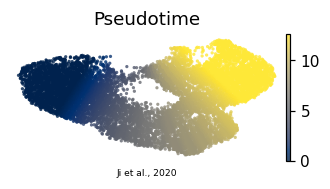

In [10]:
# ElPiGraph 'epg' uns holds ragged arrays; keep only node positions so the h5ad is serialisable
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=18, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Ji et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf')